# Phase 1 SUMO Scenario Pipeline

Choose a scenario, inspect its vehicle schedule, and compare fixed-time with actuated control. Settings are in [default.json](../../phase1_simulation/configs/default.json). Select the project kernel and run the cells in order.

In [1]:
from itertools import product
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents)
             if (path / 'phase1_simulation' / 'configs' / 'default.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the repository.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from phase1_simulation import build_network, evaluate_run, load_config, run_sumo, write_controller, write_demand

SUMO = os.environ.get('SUMO', 'sumo')
NETCONVERT = os.environ.get('NETCONVERT', 'netconvert')
config = load_config()

## 1. Scenario Candidates

Cross the five feature levels. Each row is a candidate; some combinations may require more space in the 10-minute bin than the assigned headways allow.

In [2]:
columns = ['Q', 'D', 'arrival_profile', 'turning_profile', 'B']
scenarios = pd.DataFrame(product(
    config['demand_vph'], config['directional_imbalance'], config['arrival_profiles'],
    config['turning_profiles'], config['platooning'],
), columns=columns)
scenarios.index = pd.RangeIndex(1, len(scenarios) + 1, name='scenario_id')
print(f'{len(scenarios)} candidate scenarios')
display(scenarios.head(10))

675 candidate scenarios


,Q,D,arrival_profile,turning_profile,B
scenario_id,,,,,
1,600,-0.5,uniform,through_only,0.2
2,600,-0.5,uniform,through_only,0.5
3,600,-0.5,uniform,through_only,0.8
4,600,-0.5,uniform,low_turns,0.2
5,600,-0.5,uniform,low_turns,0.5
6,600,-0.5,uniform,low_turns,0.8
7,600,-0.5,uniform,balanced_turns,0.2
8,600,-0.5,uniform,balanced_turns,0.5
9,600,-0.5,uniform,balanced_turns,0.8


### Check Departure Schedule Feasibility

Try generating each candidate's demand file in a temporary directory. The table shows the first 10 infeasible candidates and the first approach and 10-minute bin where each schedule fails. This check uses the current scheduled-headway rules and does not run SUMO.

In [ ]:
from tempfile import TemporaryDirectory

infeasible = []
with TemporaryDirectory() as temporary:
    check_path = Path(temporary) / 'demand.rou.xml'
    for scenario_id, candidate in scenarios.iterrows():
        try:
            write_demand(config, candidate, check_path)
        except ValueError as error:
            if 'cannot fit' not in str(error):
                raise
            infeasible.append({'scenario_id': scenario_id, **candidate.to_dict(), 'reason': str(error)})

infeasible_scenarios = pd.DataFrame(infeasible, columns=['scenario_id', *scenarios.columns, 'reason'])
print(f'{len(infeasible_scenarios)} of {len(scenarios)} candidates cannot be scheduled.')
display(infeasible_scenarios.head(10))

170 of 675 candidates cannot be scheduled.


scenario_id,Q,D,arrival_profile,turning_profile,B,reason
256,1200,-0.5,sustained_peak,through_only,0.2,"Approach E, bin 1: 180 vehicles cannot fit in 600 s at target B=0.2 with 2 s short gaps and long gaps above 3 s."
259,1200,-0.5,sustained_peak,low_turns,0.2,"Approach E, bin 1: 180 vehicles cannot fit in 600 s at target B=0.2 with 2 s short gaps and long gaps above 3 s."
262,1200,-0.5,sustained_peak,balanced_turns,0.2,"Approach E, bin 1: 180 vehicles cannot fit in 600 s at target B=0.2 with 2 s short gaps and long gaps above 3 s."
265,1200,-0.5,sustained_peak,left_heavy,0.2,"Approach E, bin 1: 180 vehicles cannot fit in 600 s at target B=0.2 with 2 s short gaps and long gaps above 3 s."
268,1200,-0.5,sustained_peak,right_heavy,0.2,"Approach E, bin 1: 180 vehicles cannot fit in 600 s at target B=0.2 with 2 s short gaps and long gaps above 3 s."
271,1200,-0.5,sharp_peak,through_only,0.2,"Approach E, bin 1: 225 vehicles cannot fit in 600 s at target B=0.2 with 2 s short gaps and long gaps above 3 s."
272,1200,-0.5,sharp_peak,through_only,0.5,"Approach E, bin 1: 225 vehicles cannot fit in 600 s at target B=0.5 with 2 s short gaps and long gaps above 3 s."
274,1200,-0.5,sharp_peak,low_turns,0.2,"Approach E, bin 1: 226 vehicles cannot fit in 600 s at target B=0.2 with 2 s short gaps and long gaps above 3 s."
275,1200,-0.5,sharp_peak,low_turns,0.5,"Approach E, bin 1: 226 vehicles cannot fit in 600 s at target B=0.5 with 2 s short gaps and long gaps above 3 s."
277,1200,-0.5,sharp_peak,balanced_turns,0.2,"Approach E, bin 1: 225 vehicles cannot fit in 600 s at target B=0.2 with 2 s short gaps and long gaps above 3 s."


### Feasible Scenario Combinations

Each panel represents a demand and directional imbalance pair. Rows show turning profiles, columns show arrival profiles, and cell labels list the platooning targets B that fit the scheduled headway rules. Blank cells have no feasible target. The color indicates how many targets fit. This figure shows schedule feasibility before simulation.

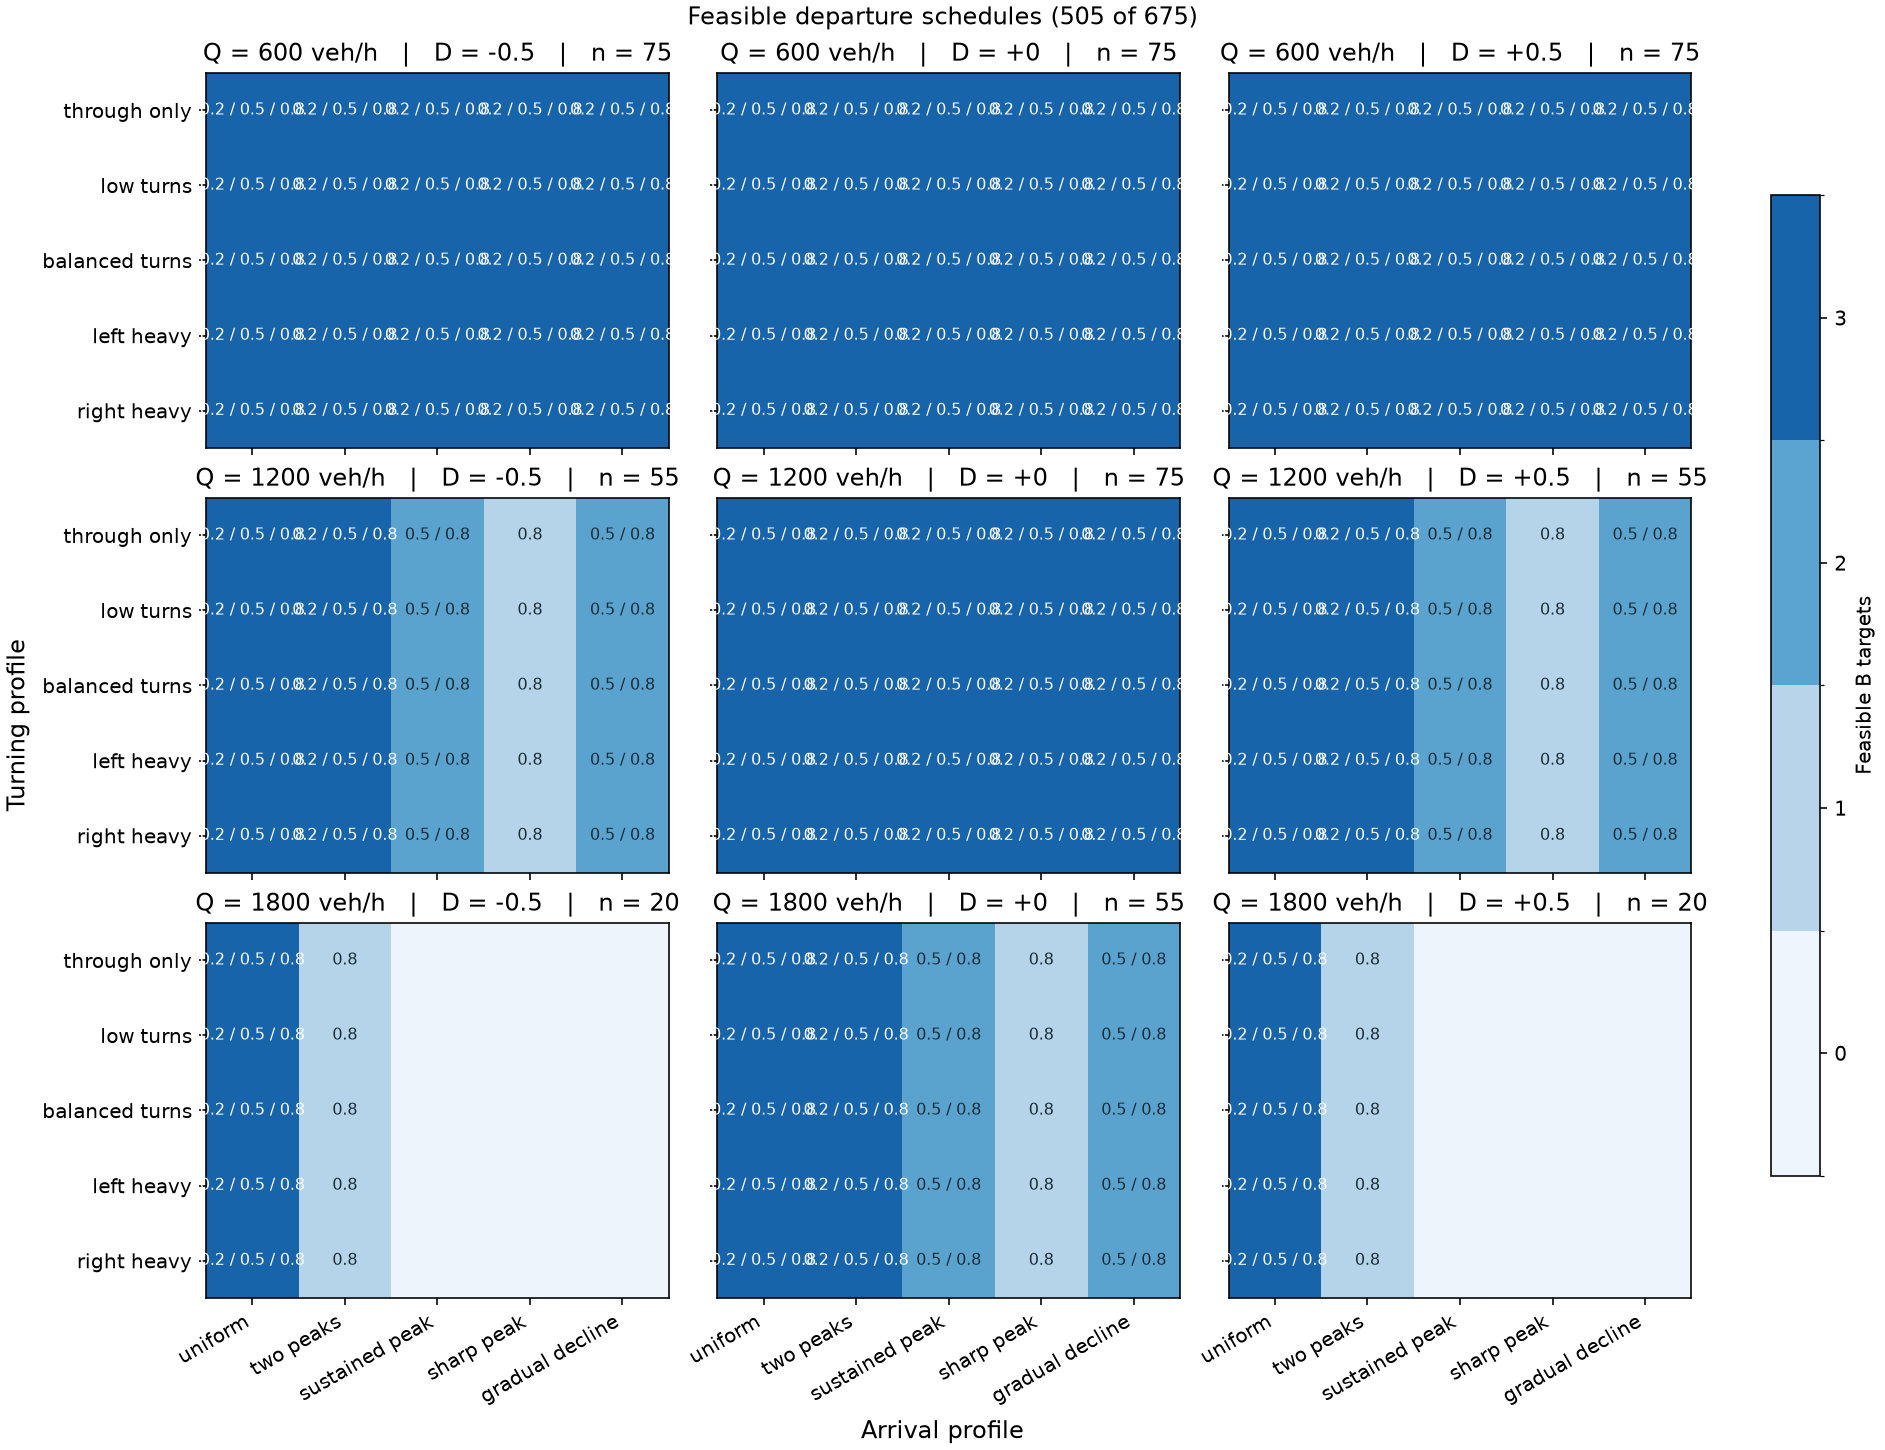

In [ ]:
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap

feasible_scenarios = scenarios.drop(index=infeasible_scenarios['scenario_id'])
arrivals = list(config['arrival_profiles'])
turns = list(config['turning_profiles'])
demands = config['demand_vph']
imbalances = config['directional_imbalance']
levels = len(config['platooning'])

palette = ListedColormap(plt.get_cmap('Blues')(np.linspace(.05, .8, levels + 1)))
norm = BoundaryNorm(np.arange(-.5, levels + 1.5), palette.N)
fig, axes = plt.subplots(len(demands), len(imbalances), figsize=(13, 10),
                         sharex=True, sharey=True, squeeze=False, layout='constrained')
for row, demand in enumerate(demands):
    for column, imbalance in enumerate(imbalances):
        ax = axes[row, column]
        group = feasible_scenarios.loc[feasible_scenarios['Q'].eq(demand)
                                       & feasible_scenarios['D'].eq(imbalance)]
        targets = group.groupby(['turning_profile', 'arrival_profile'])['B'].agg(list)
        counts = np.zeros((len(turns), len(arrivals)), dtype=int)
        for y, turn in enumerate(turns):
            for x, arrival in enumerate(arrivals):
                values = targets.get((turn, arrival), [])
                counts[y, x] = len(values)
                if values:
                    ax.text(x, y, ' / '.join(f'{value:g}' for value in values),
                            ha='center', va='center', fontsize=8,
                            color='white' if len(values) == levels else '#172b35')
        image = ax.imshow(counts, cmap=palette, norm=norm, aspect='auto')
        ax.set(title=f'Q = {demand:g} veh/h   |   D = {imbalance:+g}   |   n = {len(group)}',
               xticks=range(len(arrivals)), yticks=range(len(turns)))
        ax.set_xticklabels([name.replace('_', ' ') for name in arrivals], rotation=30, ha='right')
        ax.set_yticklabels([name.replace('_', ' ') for name in turns])
fig.colorbar(image, ax=axes, ticks=range(levels + 1), label='Feasible B targets', shrink=.8)
fig.suptitle(f'Feasible departure schedules ({len(feasible_scenarios)} of {len(scenarios)})')
fig.supxlabel('Arrival profile')
fig.supylabel('Turning profile')
plt.show()

## 2. Run and Inspect One Scenario

Generate a shared demand file, inspect the scheduled counts and headways, then run both controllers. Evaluate vehicles scheduled during 5–60 minutes and allow completion through minute 75.

In [3]:
SCENARIO_ID = 380
scenario = scenarios.loc[SCENARIO_ID].to_dict()
directory = ROOT / 'results' / 'phase1_simulation' / f'scenario_{SCENARIO_ID:03d}'
demand_path = directory / 'demand.rou.xml'
vehicles, bins = write_demand(config, scenario, demand_path)
display(scenarios.loc[[SCENARIO_ID]])
display(pd.DataFrame(bins).round(3))

,Q,D,arrival_profile,turning_profile,B
scenario_id,,,,,
380,1200,0.5,uniform,low_turns,0.5


,approach,bin,L,T,R,vehicles,target_B,scheduled_B
0,N,1,8,60,8,76,0.5,0.507
1,N,2,8,60,8,76,0.5,0.507
2,N,3,8,60,8,76,0.5,0.507
3,N,4,7,60,7,74,0.5,0.507
4,N,5,7,60,7,74,0.5,0.507
5,N,6,7,60,7,74,0.5,0.507
6,E,1,3,20,3,26,0.5,0.520
7,E,2,3,20,3,26,0.5,0.520
8,E,3,3,20,3,26,0.5,0.520
9,E,4,2,20,2,24,0.5,0.522


,scheduled_vehicles,completed_vehicles,completion_rate,average_delay_s,average_queue_vehicles,average_travel_time_s
fixed,1098,1098,1.0,113.532,33.088,142.609
actuated,1098,1098,1.0,27.658,7.942,56.743


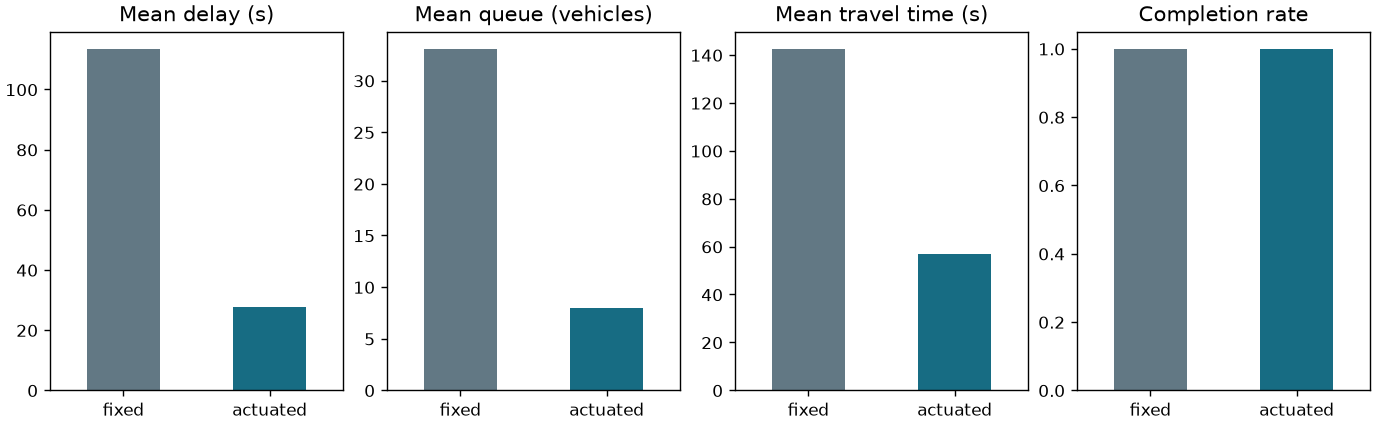

In [4]:
network = build_network(config, directory / 'network', NETCONVERT)
metrics = {}
for controller in ['fixed', 'actuated']:
    controller_network = write_controller(network, config, controller)
    run_dir = run_sumo(controller_network, demand_path, config, directory / controller, SUMO)
    metrics[controller] = evaluate_run(run_dir, vehicles, config)

comparison = pd.DataFrame.from_dict(metrics, orient='index')
display(comparison.round(3))
plots = [
    ('average_delay_s', 'Mean delay (s)'),
    ('average_queue_vehicles', 'Mean queue (vehicles)'),
    ('average_travel_time_s', 'Mean travel time (s)'),
    ('completion_rate', 'Completion rate'),
]
fig, axes = plt.subplots(1, 4, figsize=(11, 3.4), layout='constrained')
for ax, (metric, title) in zip(axes, plots):
    comparison[metric].plot.bar(ax=ax, color=['#627884', '#176c83'], rot=0)
    ax.set(title=title, xlabel='')
    if metric == 'completion_rate':
        ax.set_ylim(0, 1.05)
plt.show()

## 3. Simulate All Feasible Scenarios

Use the feasibility check above to select the scenarios. Generate one shared demand file per scenario and run both controllers against it. The road network and controller programs are generated once. Runs write to separate folders, so a small number can execute concurrently. The results table has one row per scenario and controller.

In [ ]:
from concurrent.futures import ThreadPoolExecutor

WORKERS = 4
batch_dir = ROOT / 'results' / 'phase1_simulation' / 'full_experiment'
network_path = build_network(config, batch_dir / 'network', NETCONVERT)
controller_networks = {
    controller: write_controller(network_path, config, controller)
    for controller in ('fixed', 'actuated')
}


def simulate_scenario(item):
    scenario_id, candidate = item
    scenario_dir = batch_dir / f'scenario_{scenario_id:03d}'
    demand_file = scenario_dir / 'demand.rou.xml'
    schedule, _ = write_demand(config, candidate, demand_file)
    rows = []
    for controller, controller_network in controller_networks.items():
        run_dir = run_sumo(controller_network, demand_file, config, scenario_dir / controller, SUMO)
        rows.append({'scenario_id': scenario_id, 'controller': controller,
                     **evaluate_run(run_dir, schedule, config)})
    return rows


all_rows = []
with ThreadPoolExecutor(max_workers=WORKERS) as executor:
    for count, rows in enumerate(executor.map(simulate_scenario, feasible_scenarios.iterrows()), 1):
        all_rows.extend(rows)
        if count % 50 == 0 or count == len(feasible_scenarios):
            print(f'Completed {count} of {len(feasible_scenarios)} scenarios', flush=True)

batch_results = pd.DataFrame(all_rows)
batch_results.to_csv(batch_dir / 'metrics.csv', index=False)
display(batch_results.head(6).round(3))

Completed 505 of 505 scenarios (1,010 SUMO runs).


,scenario_id,controller,scheduled_vehicles,completed_vehicles,completion_rate,average_delay_s,average_queue_vehicles,average_travel_time_s
0,1,fixed,548,548,1.0,33.544,5.059,62.524
1,1,actuated,548,548,1.0,20.504,2.894,49.515
2,2,fixed,548,548,1.0,32.772,4.942,61.706
3,2,actuated,548,548,1.0,20.428,2.892,49.389
4,3,fixed,548,548,1.0,33.873,5.133,62.807
5,3,actuated,548,548,1.0,20.107,2.798,49.047


## 4. Compare Controller Performance Across Scenarios

The scatter plots compare mean delay, queue length, and travel time. All three plots use the same scenarios with complete evaluation cohorts under both controllers. Queue length counts all stopped vehicles on inbound lanes during the common evaluation window in those scenarios. Points below each diagonal favor actuated control.

For each metric, each platooning target has a heatmap with one panel per demand and imbalance pair. Within each panel, columns are arrival profiles and rows are turning profiles. Color shows fixed-time minus actuated performance. Each metric uses its own color scale, shared across all panels and targets. Gray marks an infeasible schedule. Hatched cells mark simulated scenarios with an incomplete evaluation cohort.

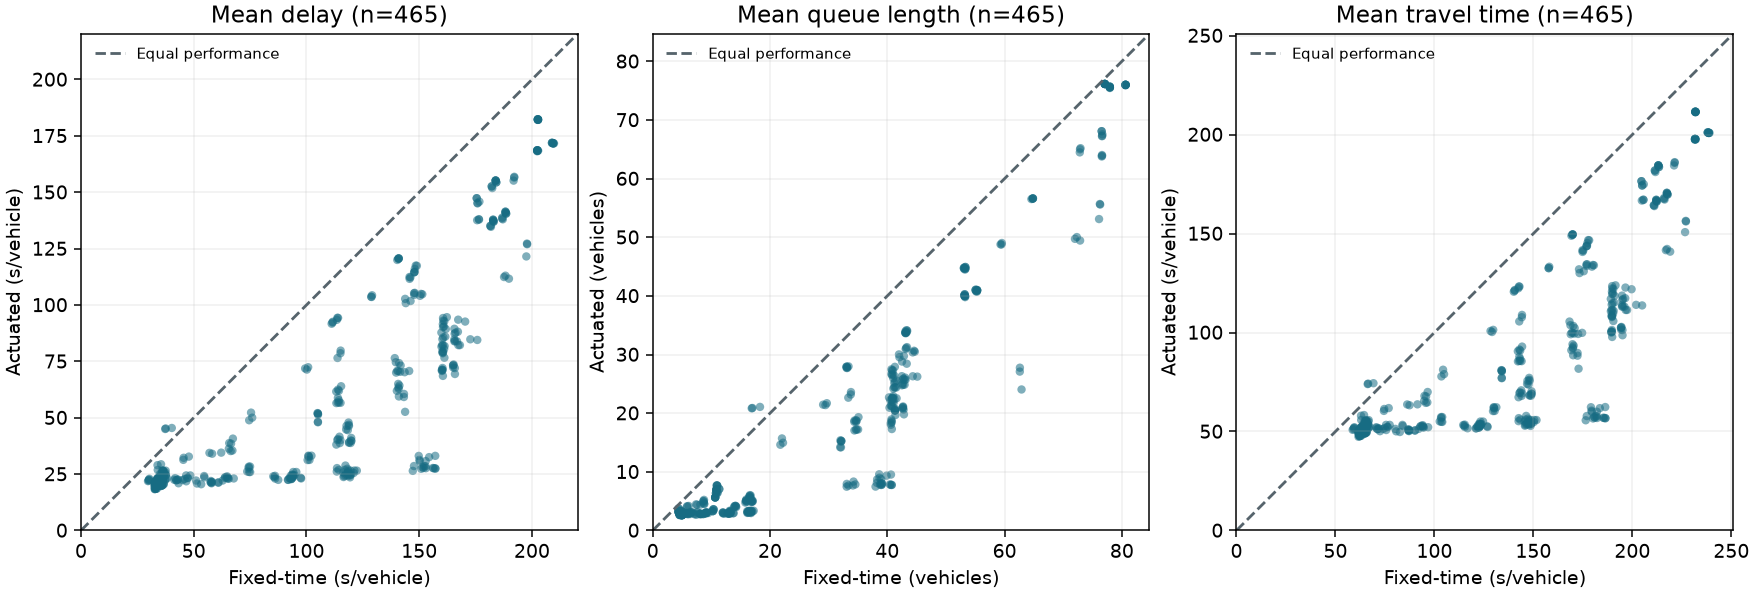

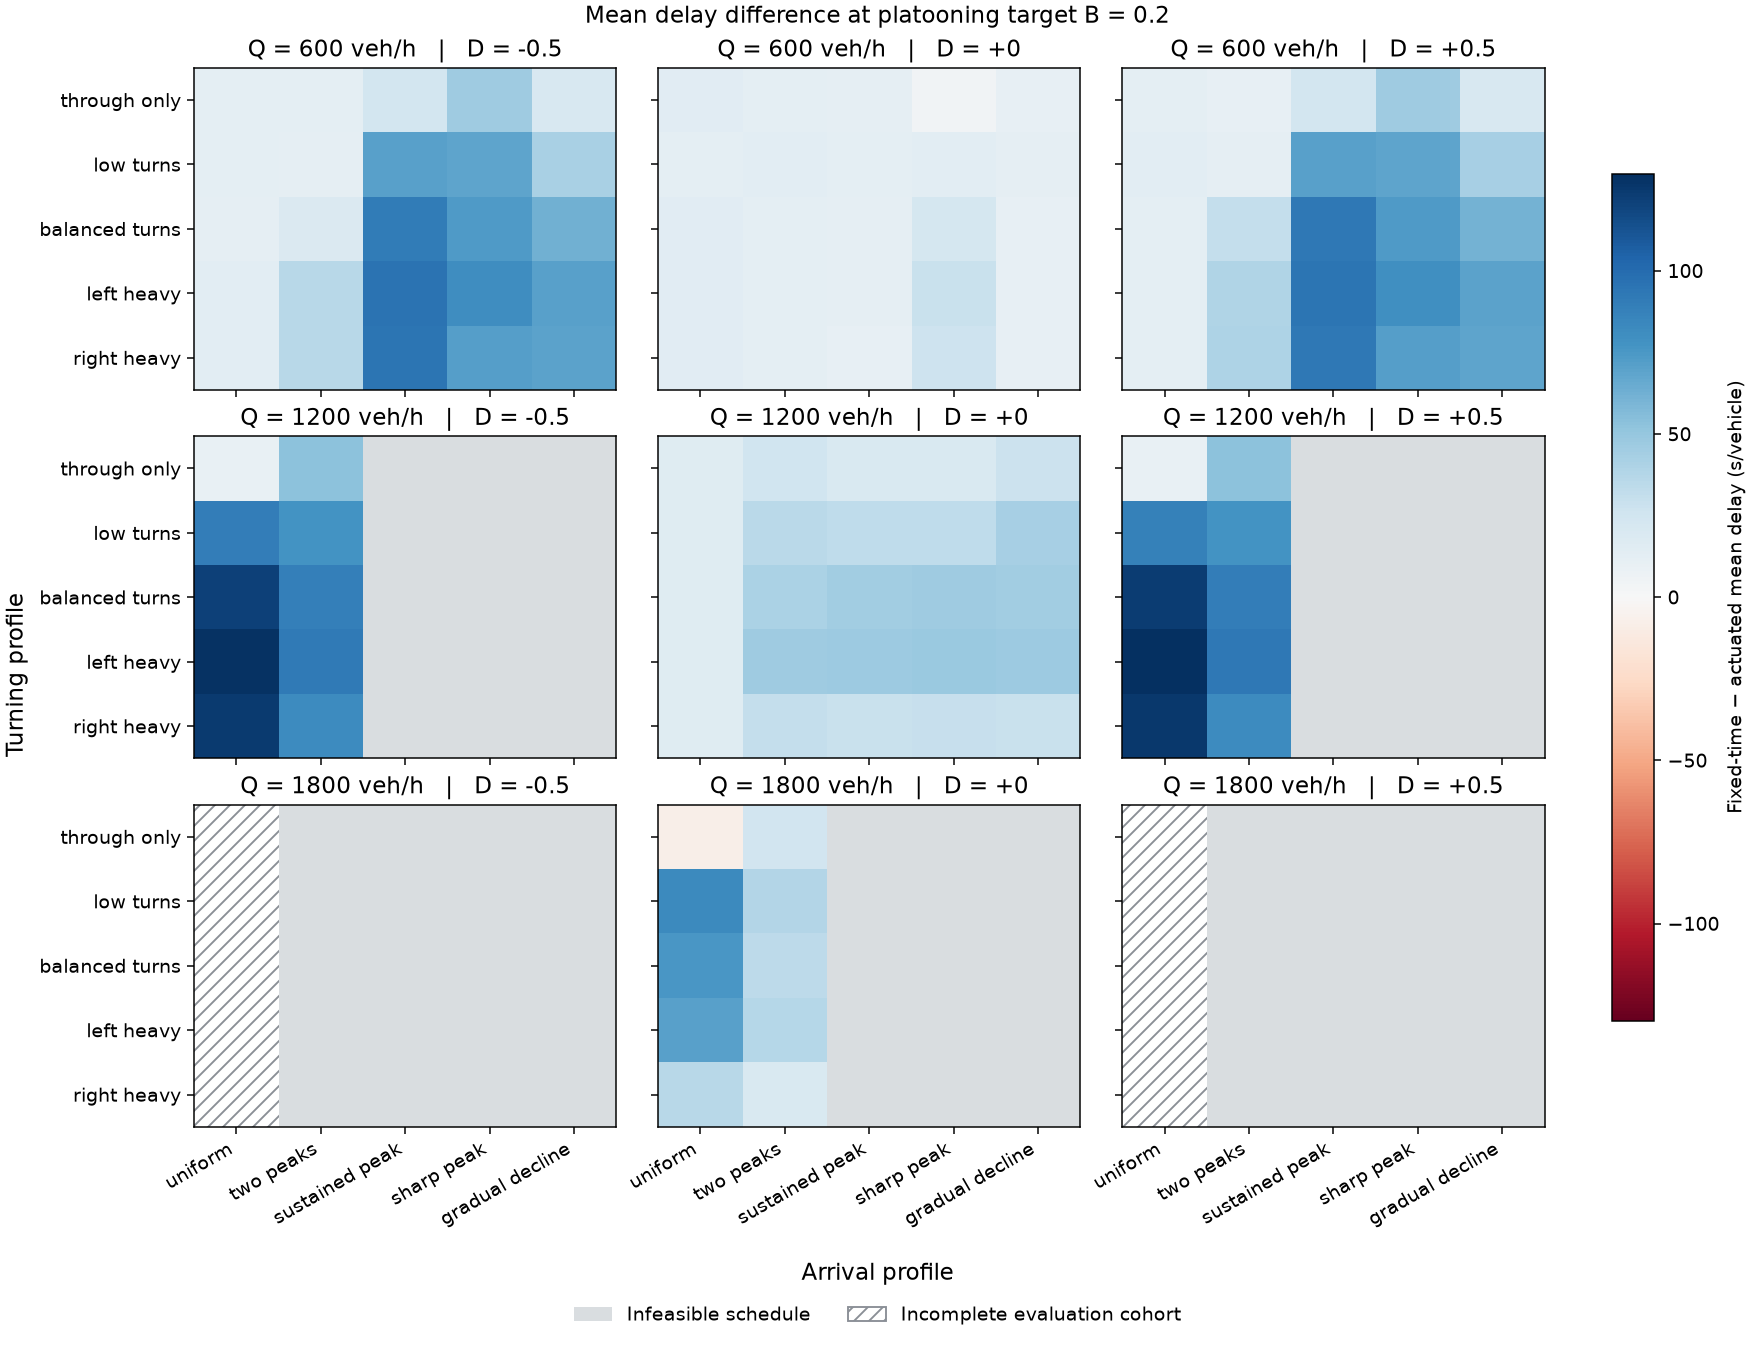

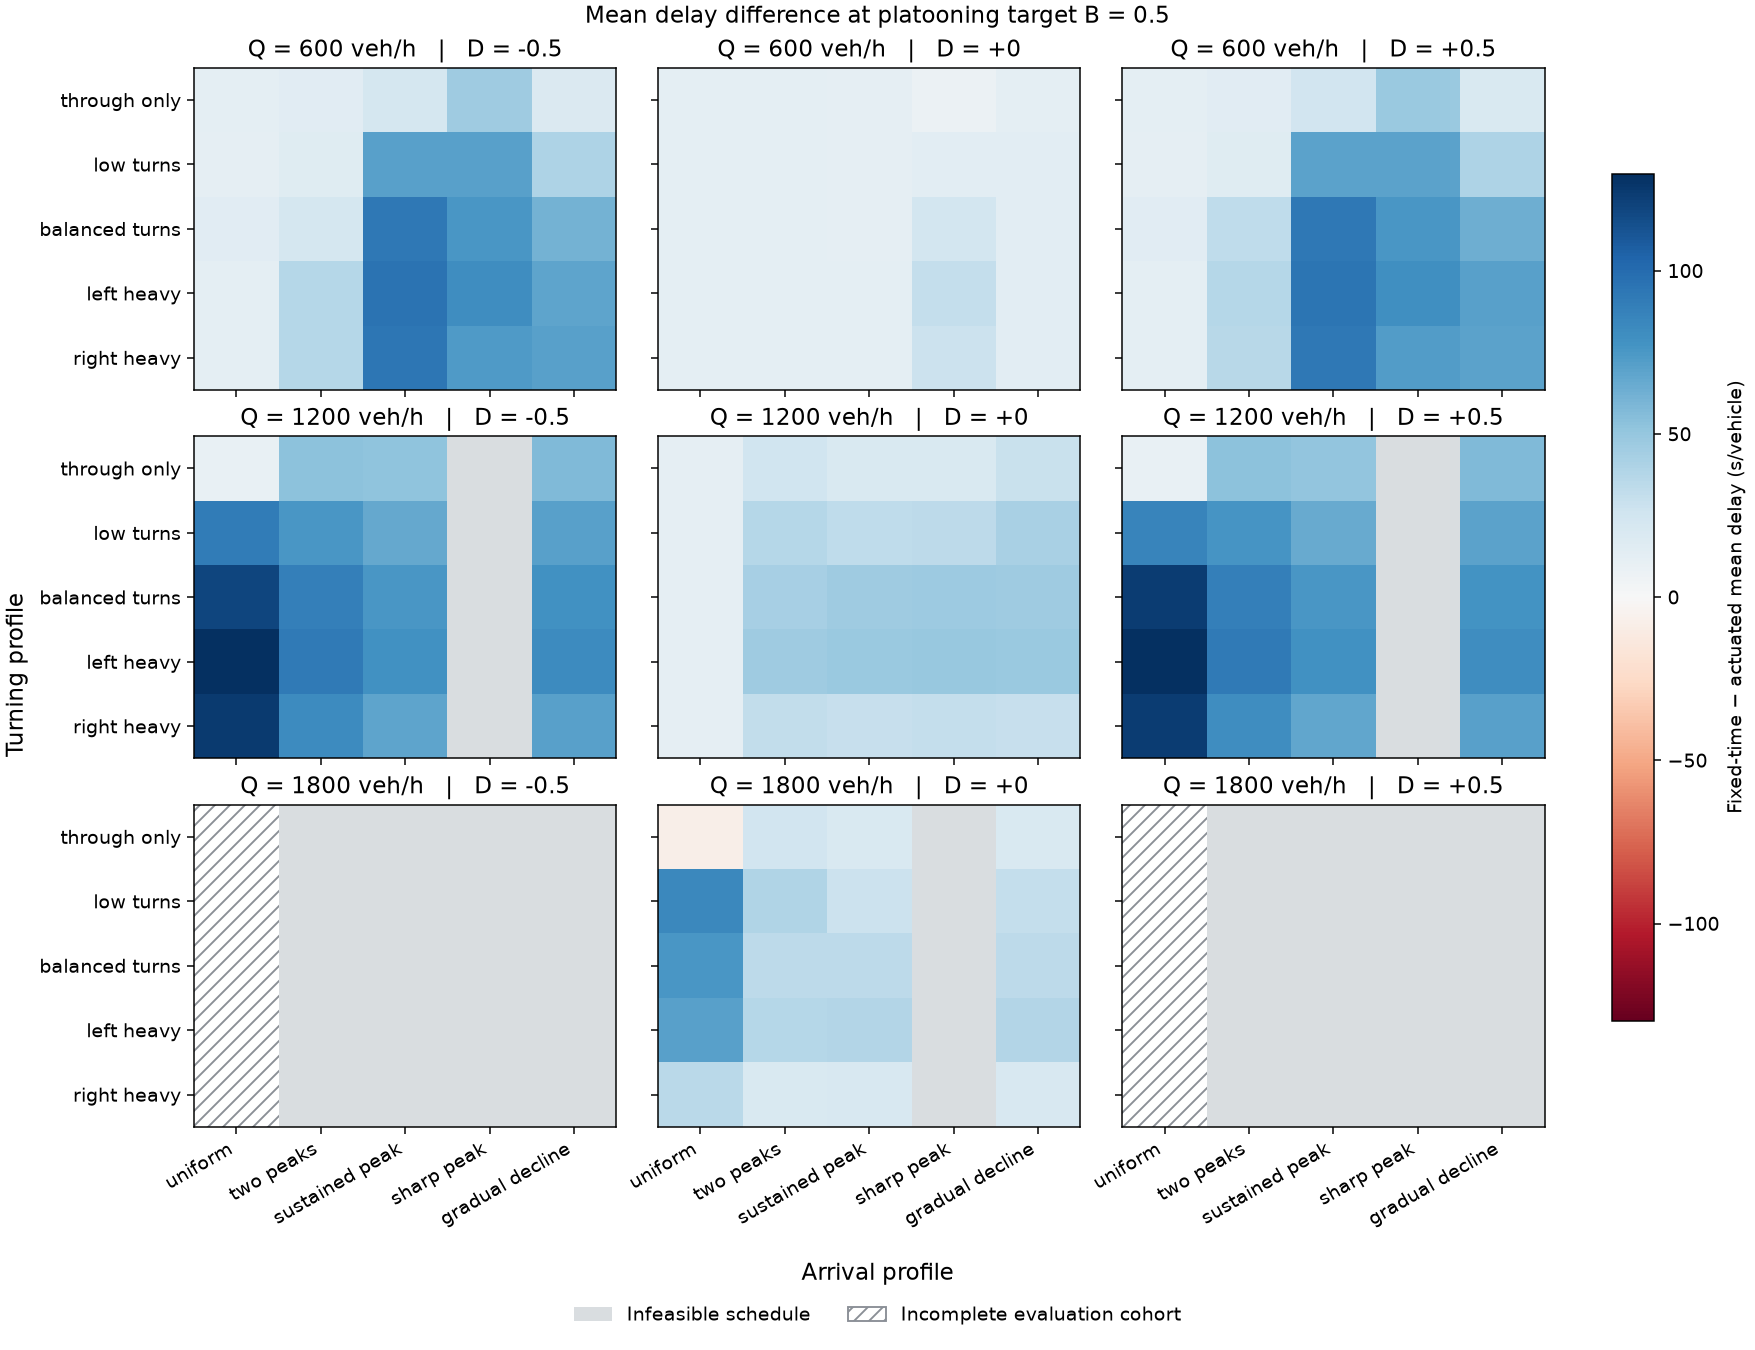

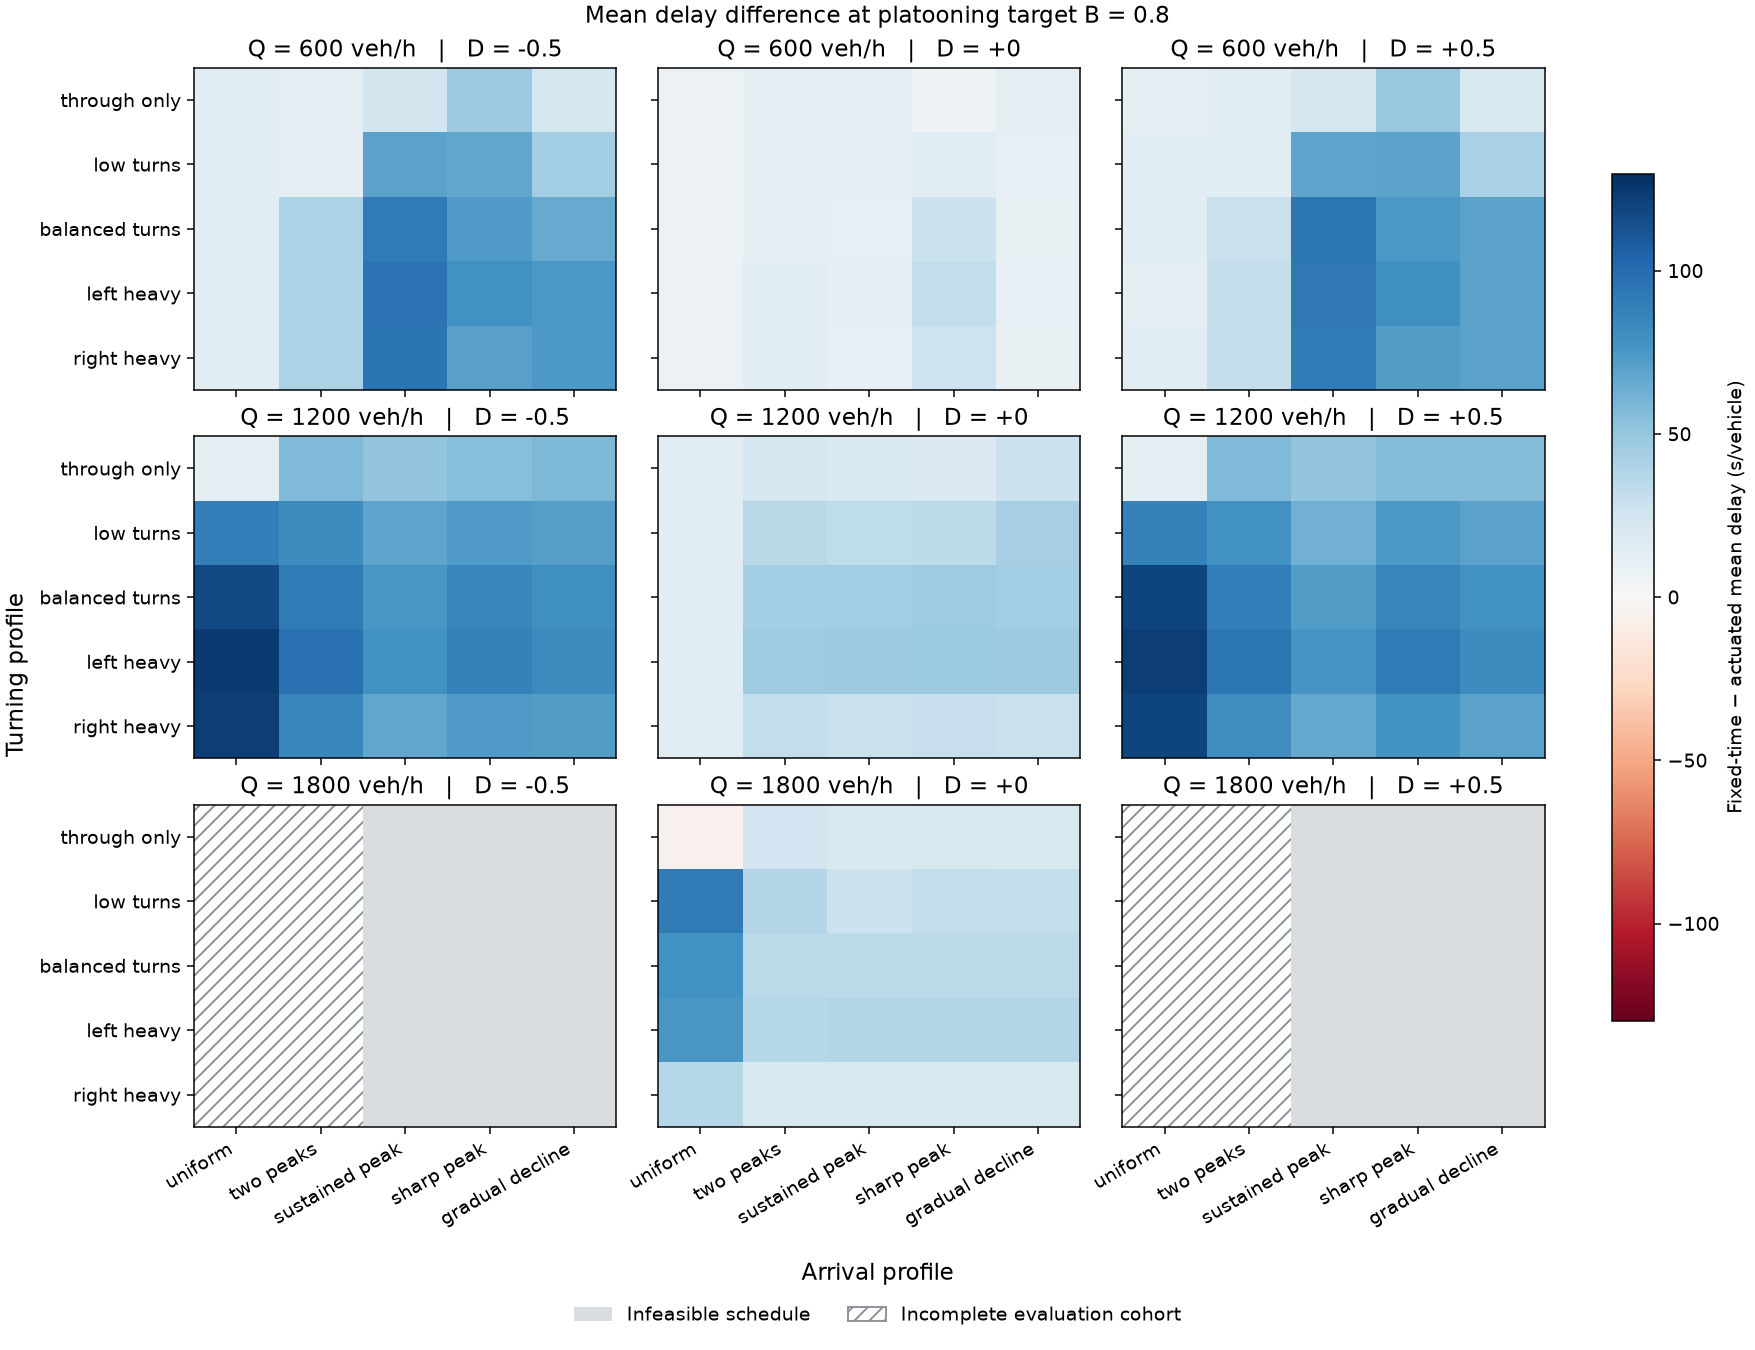

In [ ]:
from matplotlib.patches import Patch, Rectangle

delays = batch_results.pivot(index='scenario_id', columns='controller', values='average_delay_s')
complete = batch_results['completed_vehicles'].eq(batch_results['scheduled_vehicles'])
complete_pairs = complete.groupby(batch_results['scenario_id']).all()
comparable_delays = delays.loc[complete_pairs & delays.notna().all(axis=1)]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), layout='constrained')
for ax, (metric, label, unit) in zip(axes, [
    ('average_delay_s', 'Mean delay', 's/vehicle'),
    ('average_queue_vehicles', 'Mean queue length', 'vehicles'),
    ('average_travel_time_s', 'Mean travel time', 's/vehicle'),
]):
    pairs = batch_results.pivot(index='scenario_id', columns='controller', values=metric).dropna()
    pairs = pairs.loc[pairs.index.intersection(comparable_delays.index)]
    limit = max(1, float(pairs.max().max())) * 1.05
    ax.plot([0, limit], [0, limit], linestyle='--', color='#56646c', label='Equal performance')
    ax.scatter(pairs['fixed'], pairs['actuated'], color='#176c83',
               alpha=.55, s=20, edgecolors='none')
    ax.set(xlim=(0, limit), ylim=(0, limit), aspect='equal',
           xlabel=f'Fixed-time ({unit})', ylabel=f'Actuated ({unit})',
           title=f'{label} (n={len(pairs)})')
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=.2)
plt.show()


def plot_metric_gap(metric, label, unit):
    pairs = batch_results.pivot(index='scenario_id', columns='controller', values=metric)
    pairs = pairs.reindex(comparable_delays.index)
    gap = pairs['fixed'] - pairs['actuated']
    gap_limit = max(1, float(gap.abs().max()))
    for target in config['platooning']:
        fig, axes = plt.subplots(len(demands), len(imbalances), figsize=(13, 10),
                                 sharex=True, sharey=True, squeeze=False, layout='constrained')
        for row, demand in enumerate(demands):
            for column, imbalance in enumerate(imbalances):
                ax = axes[row, column]
                options = scenarios.loc[scenarios['Q'].eq(demand) & scenarios['D'].eq(imbalance)
                                        & scenarios['B'].eq(target)]
                ids = options.reset_index().pivot(index='turning_profile', columns='arrival_profile',
                                                  values='scenario_id').reindex(index=turns, columns=arrivals)
                gaps = np.full(ids.shape, np.nan)
                for y, row_ids in enumerate(ids.to_numpy()):
                    for x, scenario_id in enumerate(row_ids):
                        if scenario_id in gap.index:
                            gaps[y, x] = gap.loc[scenario_id]
                        elif scenario_id in feasible_scenarios.index:
                            ax.add_patch(Rectangle((x - .5, y - .5), 1, 1,
                                                   facecolor='white', edgecolor='#8a8f96',
                                                   hatch='///', linewidth=0, zorder=2))
                ax.set_facecolor('#d9dde0')
                image = ax.imshow(gaps, cmap='RdBu', vmin=-gap_limit, vmax=gap_limit, aspect='auto')
                ax.set(title=f'Q = {demand:g} veh/h   |   D = {imbalance:+g}',
                       xticks=range(len(arrivals)), yticks=range(len(turns)))
                ax.set_xticklabels([name.replace('_', ' ') for name in arrivals], rotation=30, ha='right')
                ax.set_yticklabels([name.replace('_', ' ') for name in turns])
        fig.colorbar(image, ax=axes, label=f'Fixed-time − actuated {label.lower()} ({unit})', shrink=.8)
        fig.legend(handles=[Patch(facecolor='#d9dde0', label='Infeasible schedule'),
                            Patch(facecolor='white', edgecolor='#8a8f96', hatch='///',
                                  label='Incomplete evaluation cohort')],
                   loc='lower center', bbox_to_anchor=(.5, .006), ncols=2, frameon=False)
        fig.suptitle(f'{label} difference at platooning target B = {target:g}')
        fig.get_layout_engine().set(rect=(0, .085, 1, .915))
        fig.supxlabel('Arrival profile', y=.048)
        fig.supylabel('Turning profile')
        plt.show()


plot_metric_gap('average_delay_s', 'Mean delay', 's/vehicle')

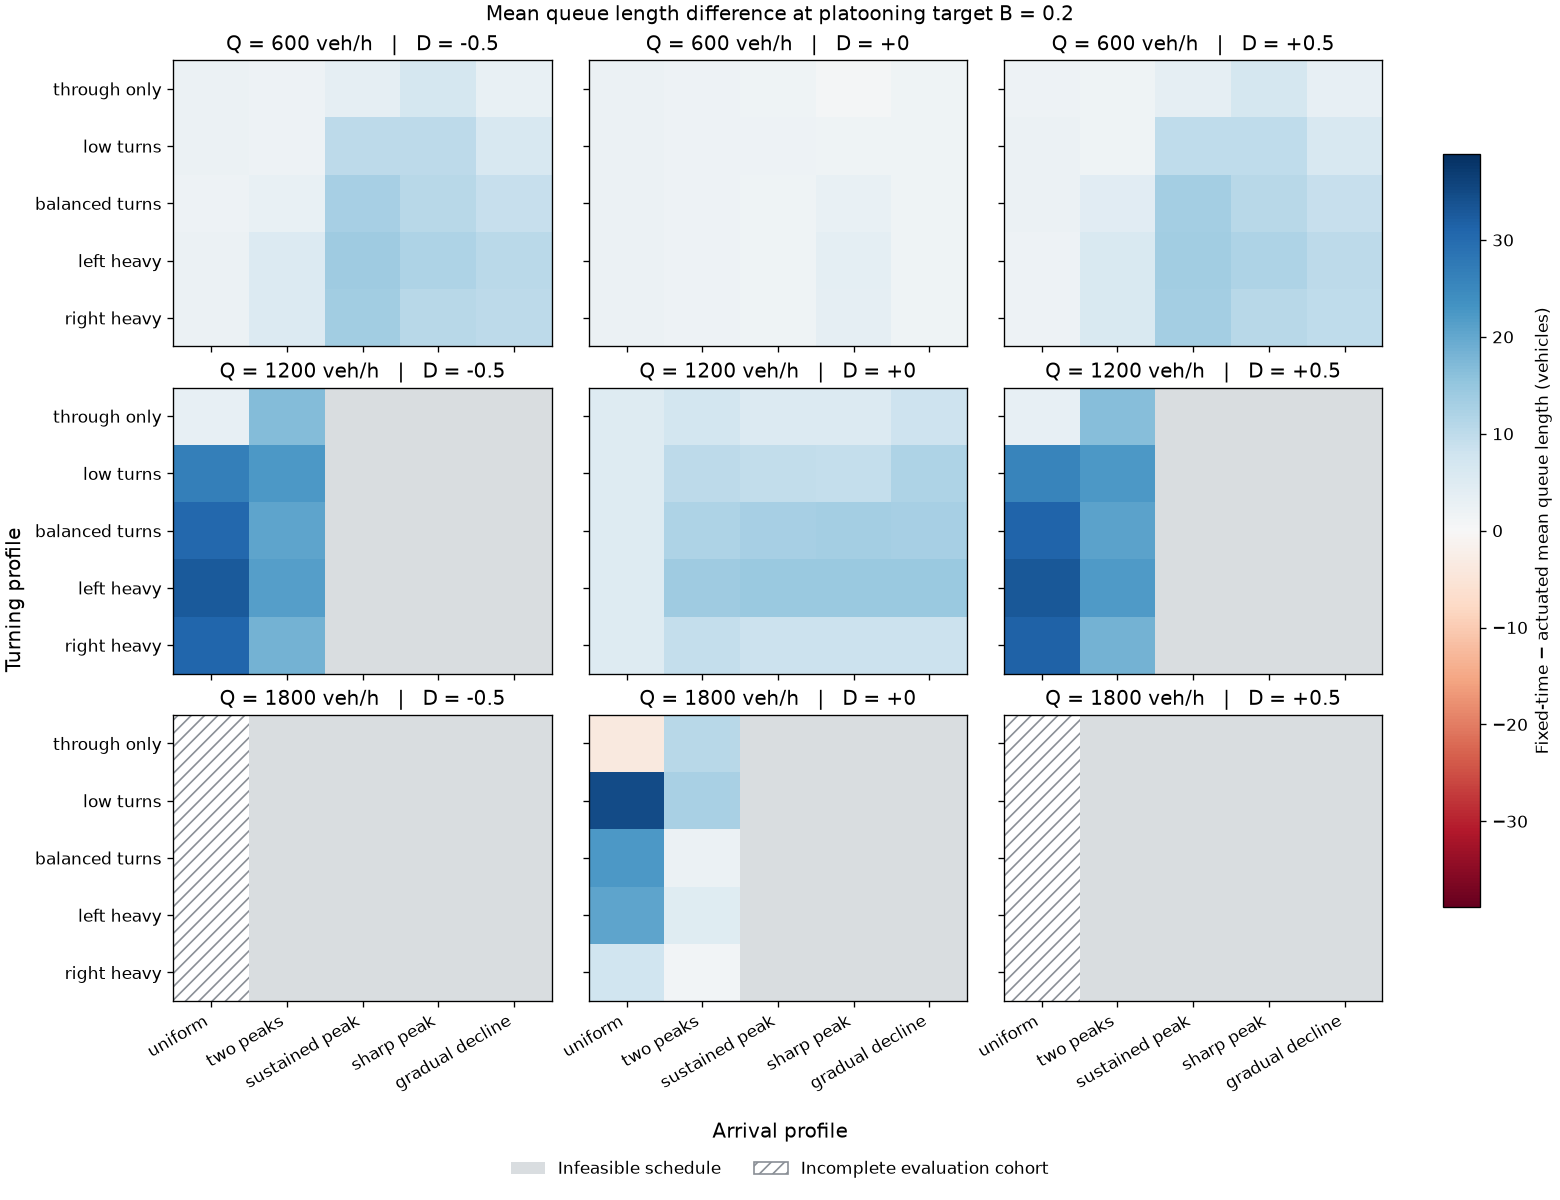

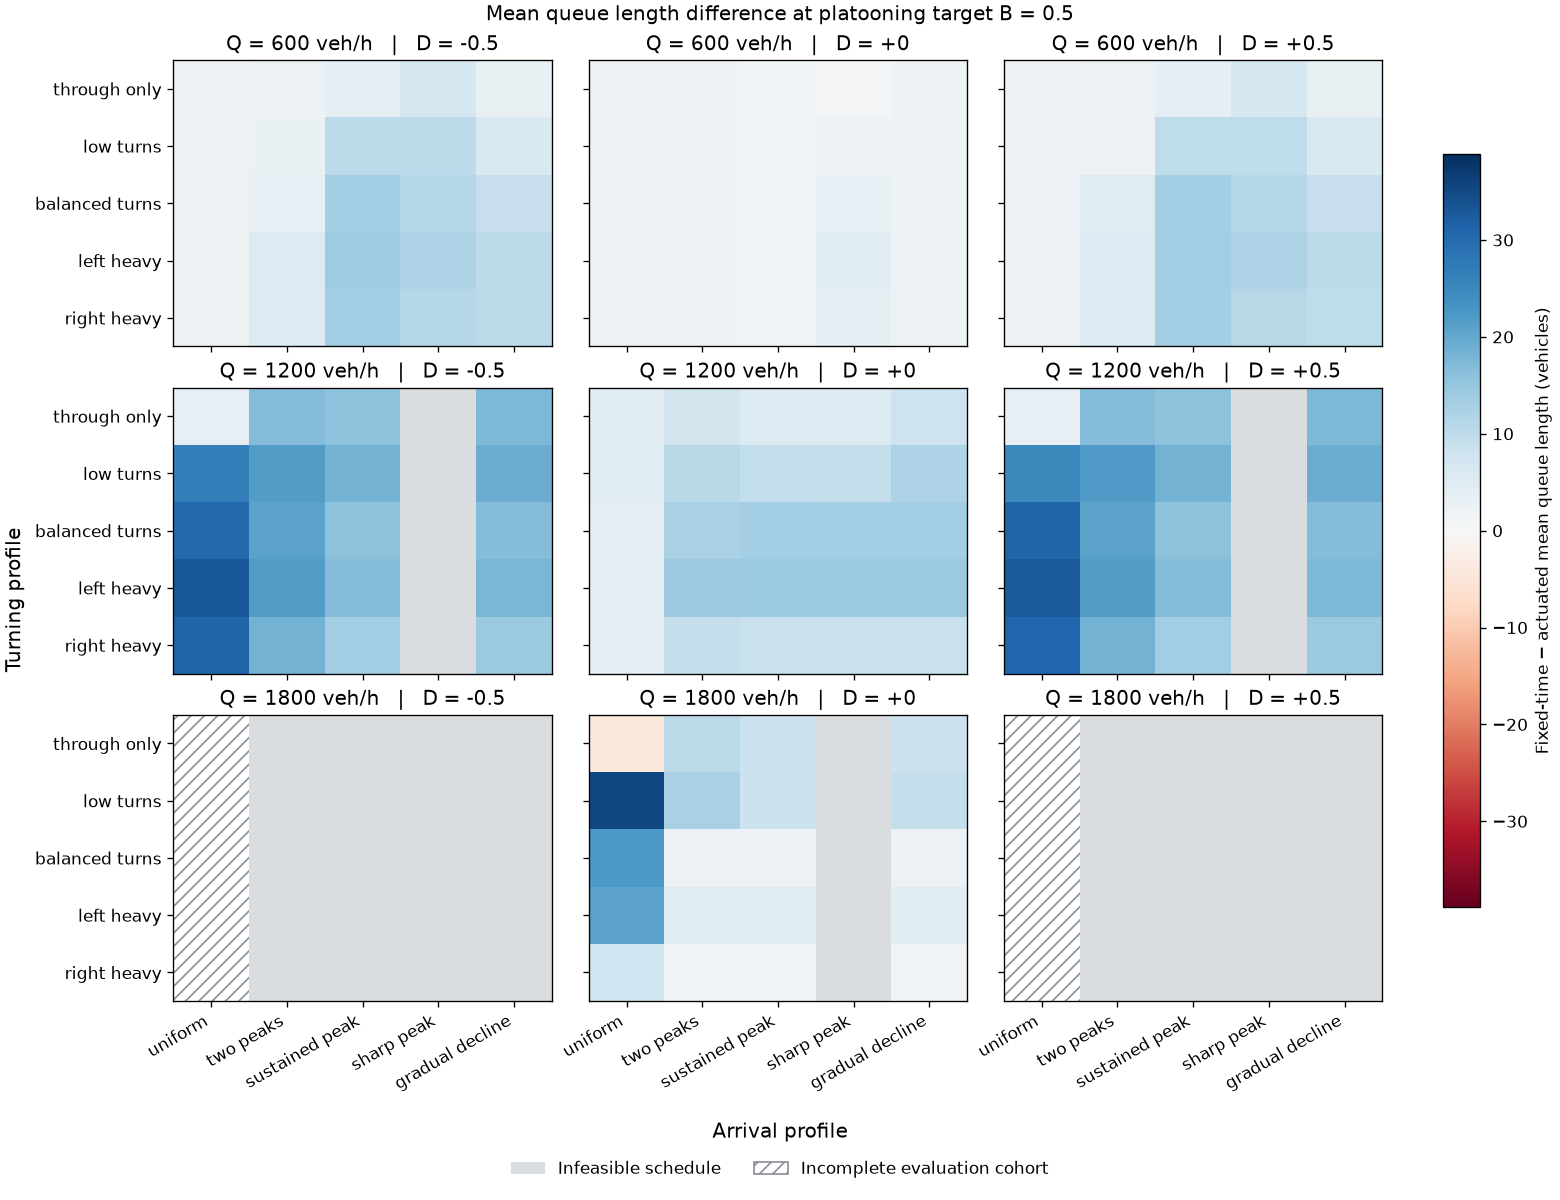

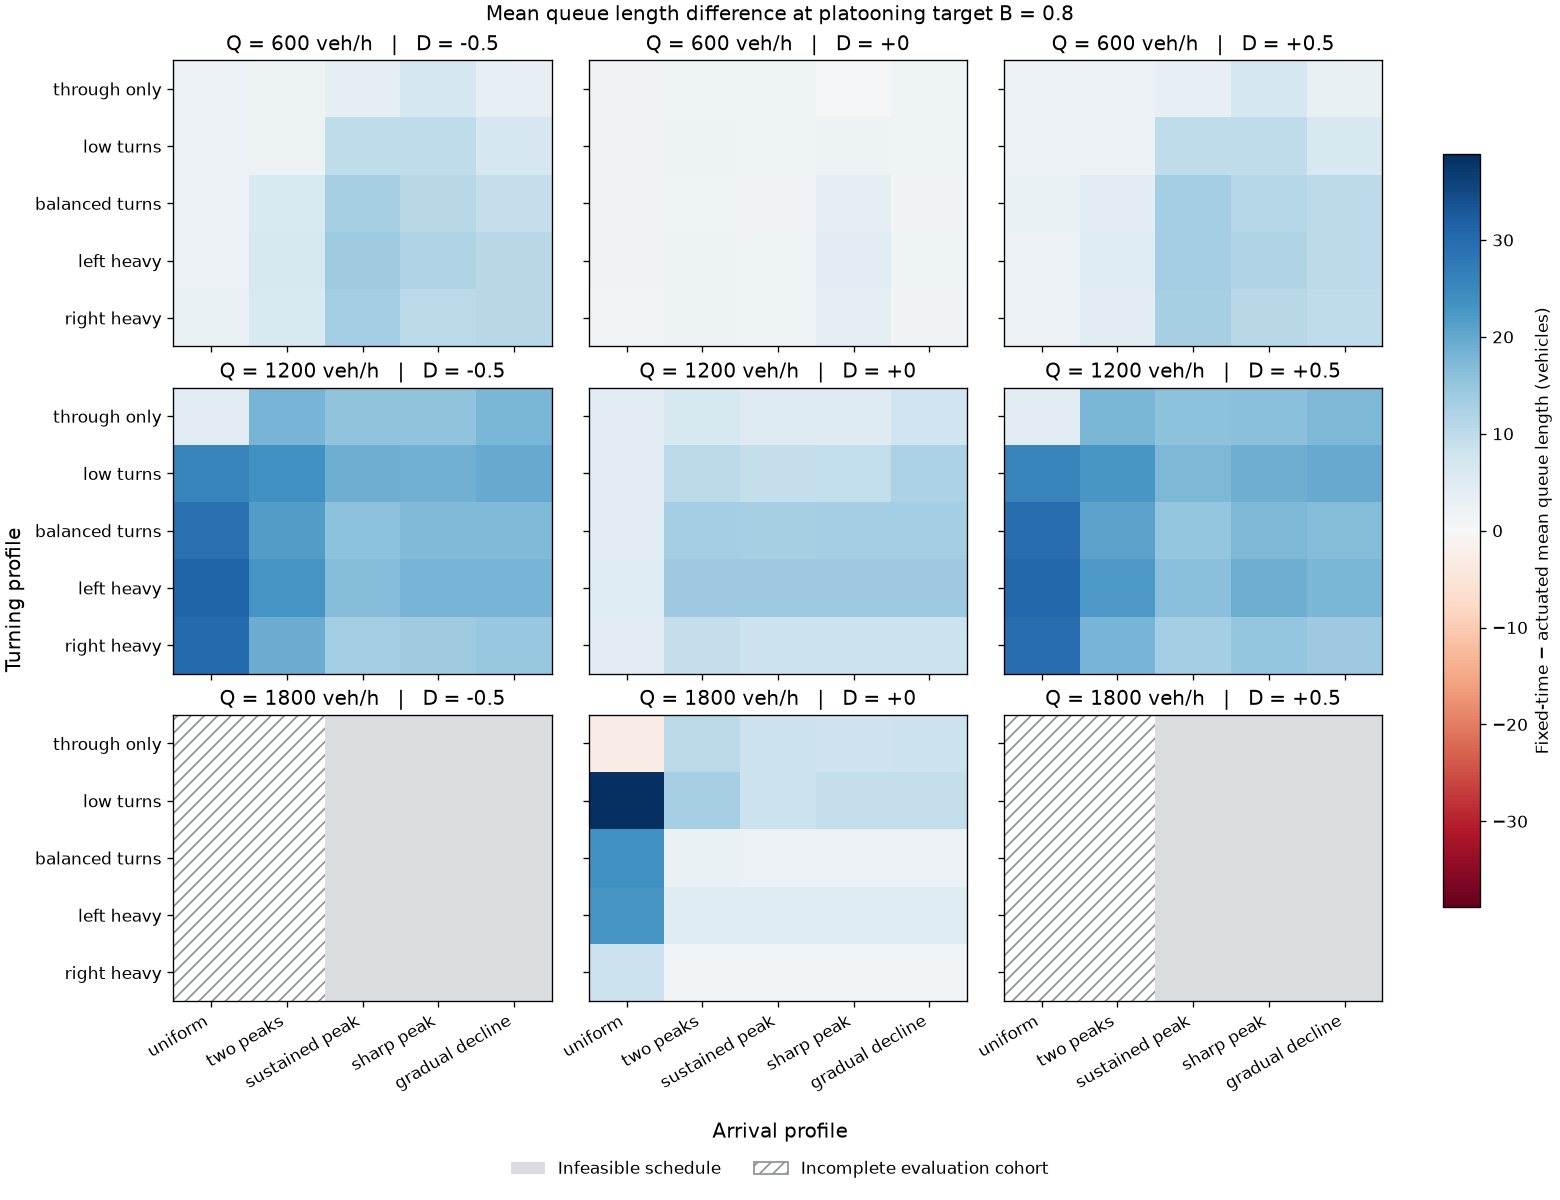

In [ ]:
plot_metric_gap('average_queue_vehicles', 'Mean queue length', 'vehicles')

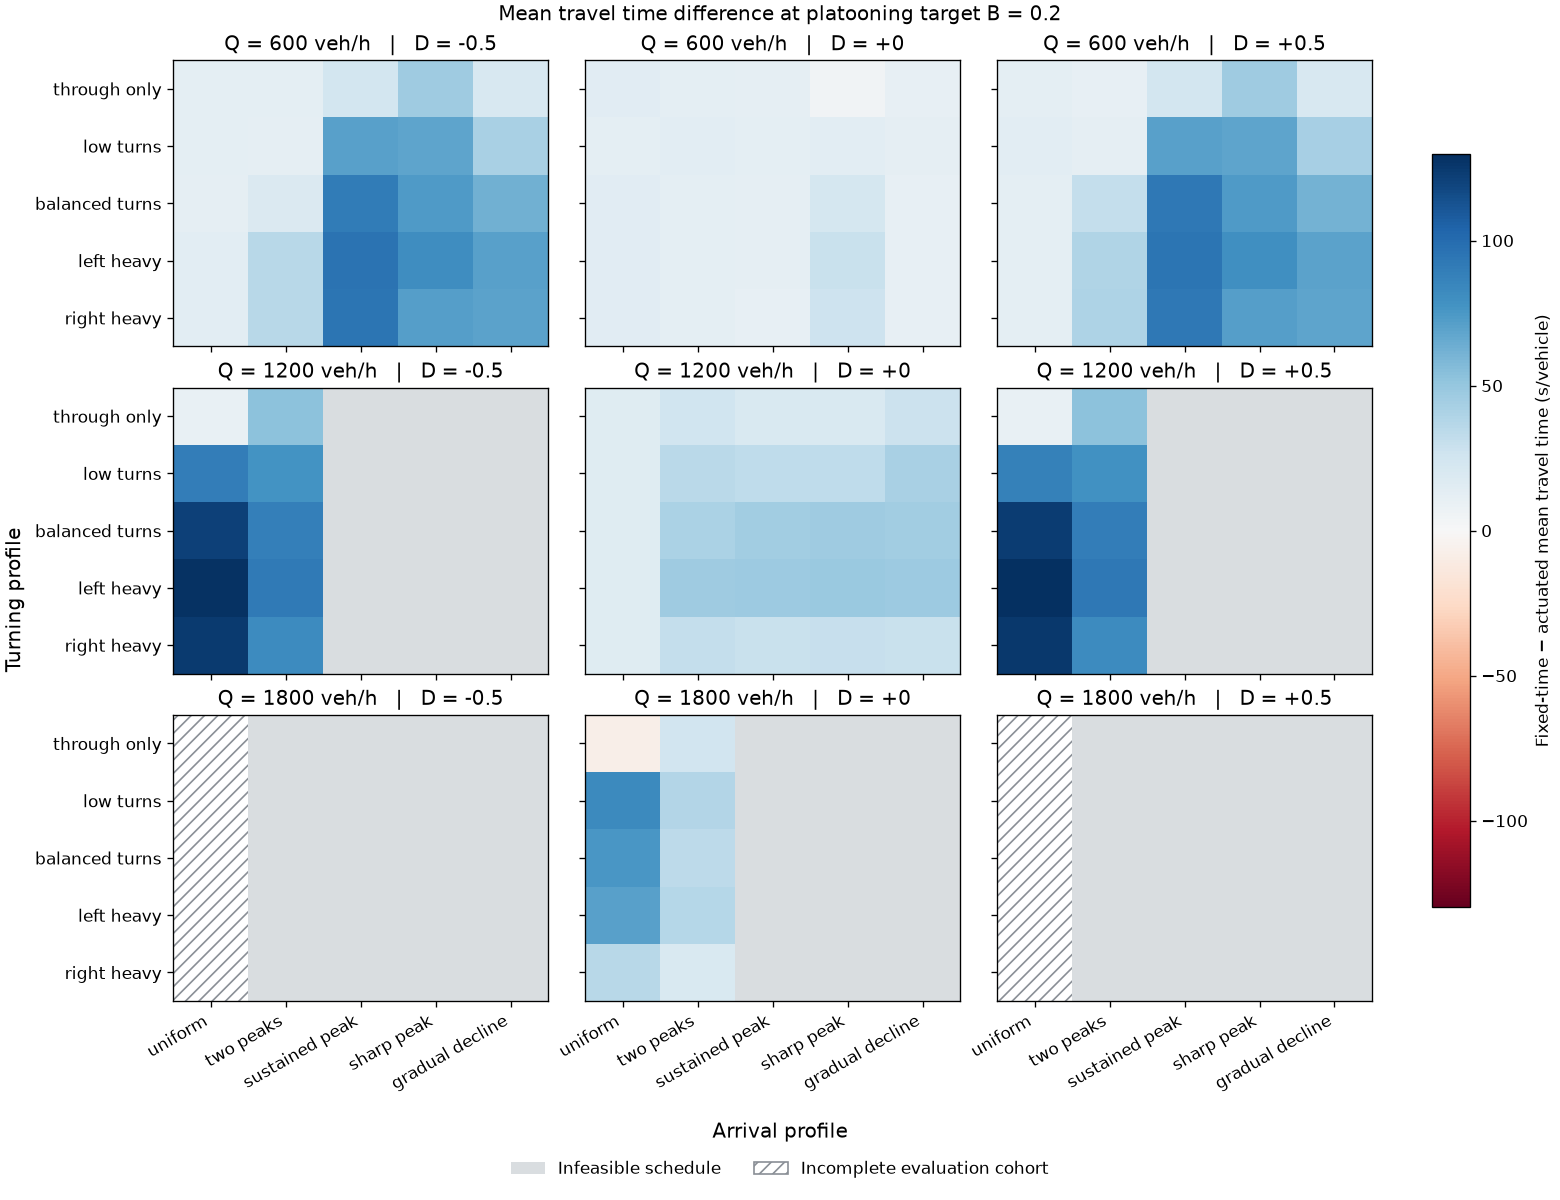

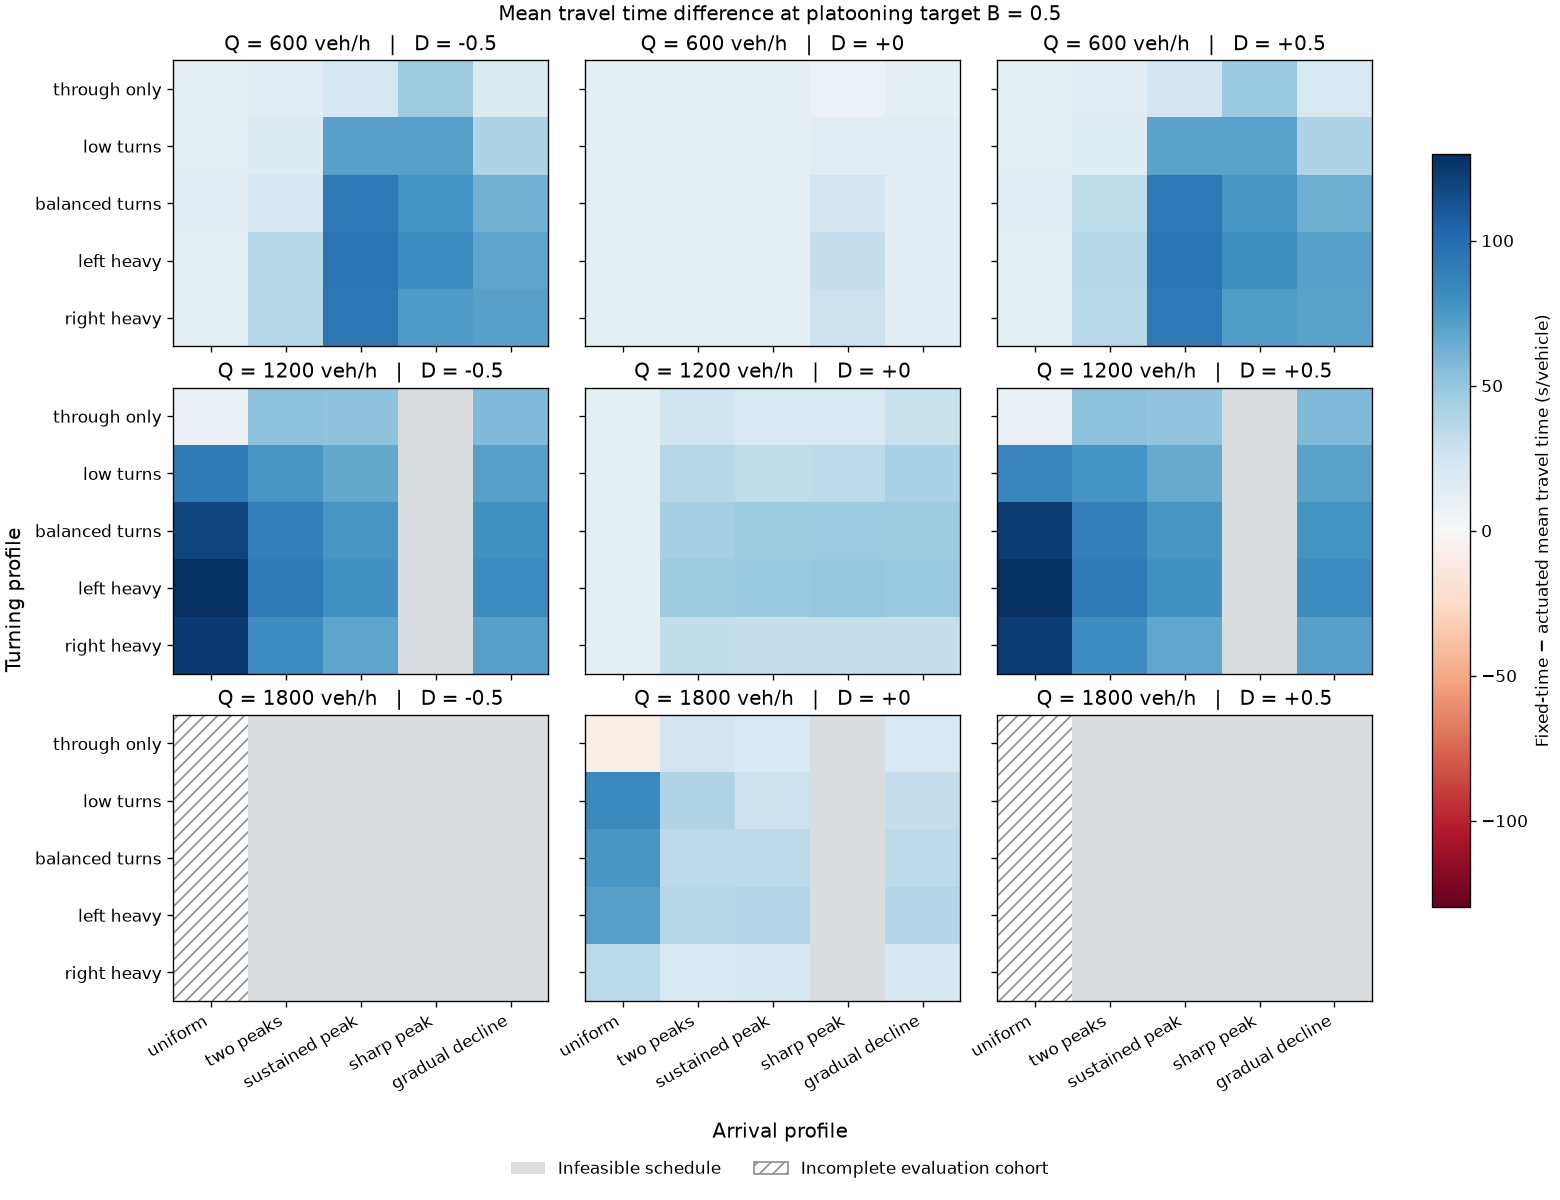

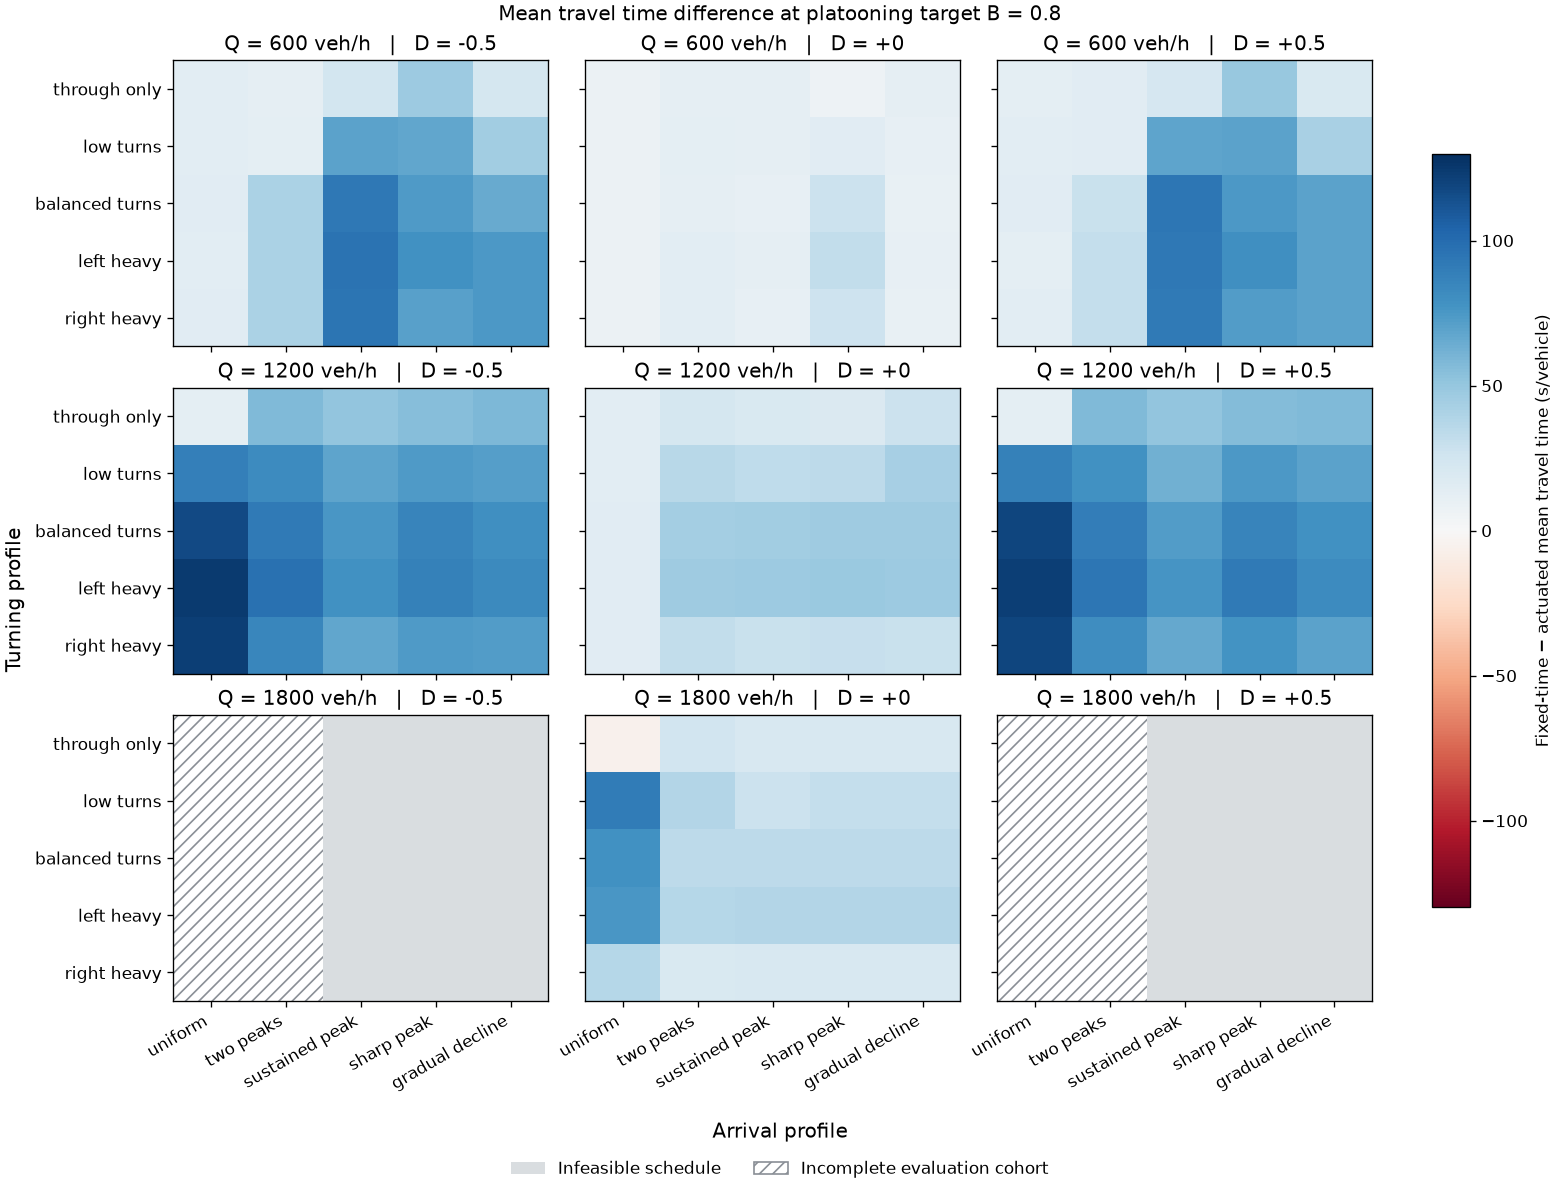

In [ ]:
plot_metric_gap('average_travel_time_s', 'Mean travel time', 's/vehicle')